/Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/gymnasium/utils/env_checker.py:372: UserWarning: WARN: A Box observation space minimum value is -infinity. This is probably too low.
  logger.warn(
/Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/gymnasium/utils/env_checker.py:376: UserWarning: WARN: A Box observation space maximum value is infinity. This is probably too high.
  logger.warn(
/Users/AlbanDERUE/Documents/CS/2A/Data Driven Control/EI/ei-rl-quadrotor/.venv/lib/python3.12/site-packages/gymnasium/utils/env_checker.py:496: UserWarning: WARN: Not able to test alternative render modes due to the environment not having a spec. Try instantiating the environment through `gymnasium.make`
  logger.warn(


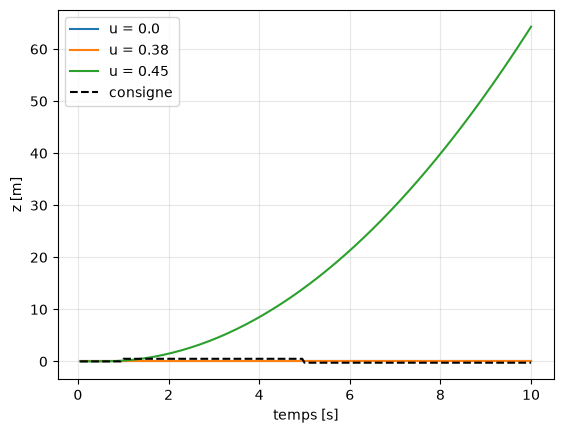

In [1]:
import sys; sys.path.append("..")
import numpy as np, matplotlib.pyplot as plt
from gymnasium.utils.env_checker import check_env
from src.env import DroneEnv, mission

env = DroneEnv(model_path="../models/lstm_az.ckpt", scaler_path="../models/lstm_az_scaler.json")
check_env(env)                          # vérifie que l'environnement respecte les règles de Gymnasium

# Test : on applique u constant et on regarde ce que fait le drone
for u in [0.0, 0.38, 0.45]:
    obs, info = env.reset()
    zs, ts = [], []
    for _ in range(200):
        obs, r, term, trunc, info = env.step(np.array([u]))
        zs.append(info["m"]["z"]); ts.append(info["m"]["t"])
    plt.plot(ts, zs, label=f"u = {u}")
plt.plot(ts, [mission(t) for t in ts], "k--", label="consigne")
plt.xlabel("temps [s]"); plt.ylabel("z [m]"); plt.legend(); plt.grid(True, alpha=0.3); plt.show()